## Financial Loan Risk Assessment and Loan Approval Prediction Summative Lab Project

### Business Problem

FinTech Innovations wants to improve the loan approval process by predicting whether an applicant is likely to become a loan risk.

### Business Impact
False Positive: Approving a risky applicant can result in significant financial losses.

False Negative: Rejecting a creditworthy applicant can lead to missed revenue opportunities.

Success Metric: The project prioritizes Recall while monitoring Precision, F1-Score and ROC-AUC.

### Objectives
The main objective is to build a machine learning classification model that helps loan officers make consistent and data-driven lending decisions.

**Specific Objectives**
Perform exploratory data analysis (EDA)
Identify important predictors of loan approval
Build and compare multiple machine learning models
Optimize model performance using hyperparameter tuning
Evaluate business impact using a cost-based framework


## Imported Libraries

In [1]:
# Importing Libraries

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Data Preparation

In [2]:
# Load data and examine its structure (Data Understanding of the available variables and overall data quality)

df = pd.read_csv("financial_loan_data.csv")

df.info()

df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         20000 non-null  int64  
 1   AnnualIncome                20000 non-null  object 
 2   CreditScore                 20000 non-null  int64  
 3   EmploymentStatus            20000 non-null  object 
 4   EducationLevel              19099 non-null  object 
 5   Experience                  20000 non-null  int64  
 6   LoanAmount                  20000 non-null  int64  
 7   LoanDuration                20000 non-null  int64  
 8   MaritalStatus               18669 non-null  object 
 9   NumberOfDependents          20000 non-null  int64  
 10  HomeOwnershipStatus         20000 non-null  object 
 11  MonthlyDebtPayments         20000 non-null  int64  
 12  CreditCardUtilizationRate   20000 non-null  float64
 13  NumberOfOpenCreditLines     200

,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,...,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,45,"$39,948.00",617,Employed,Master,22,13152,48,Married,2,...,3329.000000,0.724972,11,126928,0.199652,0.227590,419.805992,0.181077,0,49.0
1,38,"$39,709.00",628,Employed,Associate,15,26045,48,Single,1,...,3309.083333,0.935132,3,43609,0.207045,0.201077,794.054238,0.389852,0,52.0
2,47,"$40,724.00",570,Employed,Bachelor,26,17627,36,NaN,2,...,3393.666667,0.872241,6,5205,0.217627,0.212548,666.406688,0.462157,0,52.0
3,58,"$69,084.00",545,Employed,High School,34,37898,96,Single,1,...,5757.000000,0.896155,5,99452,0.300398,0.300911,1047.506980,0.313098,0,54.0
4,37,"$103,264.00",594,Employed,Associate,17,9184,36,Married,1,...,8605.333333,0.941369,5,227019,0.197184,0.175990,330.179140,0.070210,1,36.0


## # Data Overview: 

Reviewing variable data types and summary statistics before performing data preparation.


In [3]:
print("Dataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDescriptive Statistics:")
df.describe(include="all")

Dataset Shape:
(20000, 35)

Data Types:
Age                             int64
AnnualIncome                   object
CreditScore                     int64
EmploymentStatus               object
EducationLevel                 object
Experience                      int64
LoanAmount                      int64
LoanDuration                    int64
MaritalStatus                  object
NumberOfDependents              int64
HomeOwnershipStatus            object
MonthlyDebtPayments             int64
CreditCardUtilizationRate     float64
NumberOfOpenCreditLines         int64
NumberOfCreditInquiries         int64
DebtToIncomeRatio             float64
BankruptcyHistory              object
LoanPurpose                    object
PreviousLoanDefaults            int64
PaymentHistory                  int64
LengthOfCreditHistory           int64
SavingsAccountBalance         float64
CheckingAccountBalance          int64
TotalAssets                     int64
TotalLiabilities                int64
MonthlyInc

,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,...,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
count,20000.000000,20000,20000.000000,20000,19099,20000.000000,20000.000000,20000.000000,18669,20000.000000,...,20000.000000,20000.000000,20000.000000,2.000000e+04,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
unique,NaN,17516,NaN,3,5,NaN,NaN,NaN,4,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,"$15,000.00",NaN,Employed,Bachelor,NaN,NaN,NaN,Married,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,584,NaN,17036,5804,NaN,NaN,NaN,9370,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,39.752600,NaN,571.612400,NaN,NaN,17.522750,24882.867800,54.057000,NaN,1.517300,...,4891.715521,0.799918,5.002650,7.229432e+04,0.239124,0.239110,911.607052,0.402182,0.239000,50.766780
std,11.622713,NaN,50.997358,NaN,NaN,11.316836,13427.421217,24.664857,NaN,1.386325,...,3296.771598,0.120665,2.236804,1.179200e+05,0.035509,0.042205,674.583473,0.338924,0.426483,7.778262
min,18.000000,NaN,343.000000,NaN,NaN,0.000000,3674.000000,12.000000,NaN,0.000000,...,1250.000000,0.259203,0.000000,1.000000e+03,0.130101,0.113310,97.030193,0.016043,0.000000,28.800000
25%,32.000000,NaN,540.000000,NaN,NaN,9.000000,15575.000000,36.000000,NaN,0.000000,...,2629.583333,0.727379,3.000000,8.734750e+03,0.213889,0.209142,493.763700,0.179693,0.000000,46.000000
50%,40.000000,NaN,578.000000,NaN,NaN,17.000000,21914.500000,48.000000,NaN,1.000000,...,4034.750000,0.820962,5.000000,3.285550e+04,0.236157,0.235390,728.511452,0.302711,0.000000,52.000000
75%,48.000000,NaN,609.000000,NaN,NaN,25.000000,30835.000000,72.000000,NaN,2.000000,...,6163.000000,0.892333,6.000000,8.882550e+04,0.261533,0.265532,1112.770759,0.509214,0.000000,56.000000


In [4]:
print("\nMissing Values:")
print(df.isnull().sum())




Missing Values:
Age                              0
AnnualIncome                     0
CreditScore                      0
EmploymentStatus                 0
EducationLevel                 901
Experience                       0
LoanAmount                       0
LoanDuration                     0
MaritalStatus                 1331
NumberOfDependents               0
HomeOwnershipStatus              0
MonthlyDebtPayments              0
CreditCardUtilizationRate        0
NumberOfOpenCreditLines          0
NumberOfCreditInquiries          0
DebtToIncomeRatio                0
BankruptcyHistory                0
LoanPurpose                      0
PreviousLoanDefaults             0
PaymentHistory                   0
LengthOfCreditHistory            0
SavingsAccountBalance          572
CheckingAccountBalance           0
TotalAssets                      0
TotalLiabilities                 0
MonthlyIncome                    0
UtilityBillsPaymentHistory       0
JobTenure                        0
Net

### Observations
Dataset contains financial, credit, and demographic variables.
Both numerical and categorical features are present.
Several monetary variables require conversion to numeric format.

## Data Cleaning

Converting currency-formatted financial variables into numerical format for analysis and machine learning.

In [5]:



#currency_cols = []

#for col in df.columns:

#    if df[col].dtype == "object":

#        sample = str(df[col].dropna().iloc[0])

#        if "$" in sample:

#            currency_cols.append(col)

#for col in currency_cols:

money_cols = [
    "AnnualIncome",
    "SavingsAccountBalance",
    "CheckingAccountBalance",
    "TotalAssets",
    "TotalLiabilities",
    "MonthlyIncome",
    "NetWorth"
]

for col in money_cols:

    df[col] = (
        df[col]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
    )

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

#print("Converted:")
#print(currency_cols)
#print(money_cols)

In [6]:
df[money_cols].dtypes

AnnualIncome              float64
SavingsAccountBalance     float64
CheckingAccountBalance      int64
TotalAssets                 int64
TotalLiabilities            int64
MonthlyIncome             float64
NetWorth                    int64
dtype: object

In [7]:
df[money_cols].describe()

,AnnualIncome,SavingsAccountBalance,CheckingAccountBalance,TotalAssets,TotalLiabilities,MonthlyIncome,NetWorth
count,20000.000000,19428.000000,20000.000000,2.000000e+04,2.000000e+04,20000.000000,2.000000e+04
mean,59161.473550,4949.148446,1782.555100,9.696440e+04,3.625241e+04,4891.715521,7.229432e+04
std,40350.845168,6628.404969,2245.378812,1.207999e+05,4.725151e+04,3296.771598,1.179200e+05
min,15000.000000,73.000000,24.000000,2.098000e+03,3.720000e+02,1250.000000,1.000000e+03
25%,31679.000000,1542.000000,551.000000,3.118025e+04,1.119675e+04,2629.583333,8.734750e+03
50%,48566.000000,2988.500000,1116.000000,6.069900e+04,2.220300e+04,4034.750000,3.285550e+04
75%,74391.000000,5869.250000,2126.000000,1.174052e+05,4.314650e+04,6163.000000,8.882550e+04
max,485341.000000,200089.000000,52572.000000,2.619627e+06,1.417302e+06,25000.000000,2.603208e+06


### Intepretation:

Financial variables have been successfully converted into numerical format and are ready for analysis.

## Missing Value Analysis

Identifying features with missing observations and assess the level of missingness.

In [8]:
# Missing Values Analysis

missing_df = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Percentage": round(
        df.isnull().mean()*100,
        2
    )
})

missing_df = missing_df[
    missing_df["Missing Count"] > 0
]

missing_df.sort_values(
    by="Missing Count",
    ascending=False
)



,Missing Count,Percentage
MaritalStatus,1331,6.65
EducationLevel,901,4.50
SavingsAccountBalance,572,2.86


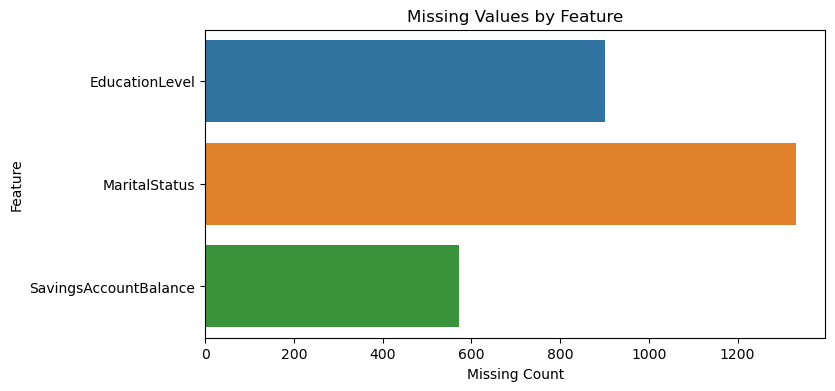

In [9]:
plt.figure(figsize=(8,4))

sns.barplot(
    x=missing_df["Missing Count"],
    y=missing_df.index
)

plt.title("Missing Values by Feature")
plt.xlabel("Missing Count")
plt.ylabel("Feature")

plt.show()

### Business Interpretation
Missing values are concentrated in a few features and can be handled through imputation without significant information loss.

# EDA

## Target Variable Analysis

In [10]:
target = "LoanApproved"

df[target].value_counts()

LoanApproved
0    15220
1     4780
Name: count, dtype: int64

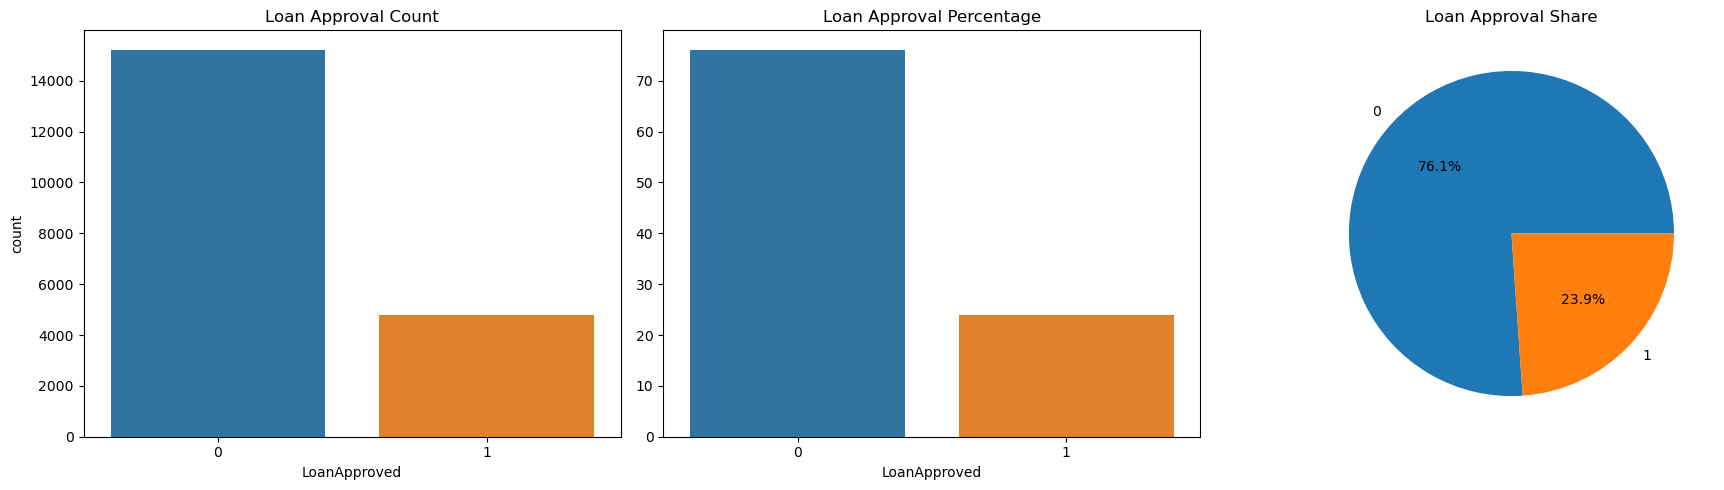

In [11]:
# Analyzing the distribution of approved and rejected loan applications.
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18,5)
)

sns.countplot(
    data=df,
    x="LoanApproved",
    ax=axes[0]
)

axes[0].set_title("Loan Approval Count")

approval_pct = (
    df["LoanApproved"]
    .value_counts(normalize=True)
    * 100
)

sns.barplot(
    x=approval_pct.index,
    y=approval_pct.values,
    ax=axes[1]
)

axes[1].set_title(
    "Loan Approval Percentage"
)

df["LoanApproved"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    ax=axes[2]
)

axes[2].set_title(
    "Loan Approval Share"
)

axes[2].set_ylabel("")

plt.tight_layout()

plt.show()

### Interpretation
The target distribution provides insight into class balance and helps determine appropriate evaluation metrics for model assessment.

## Financial Variable Distributions
Examining the distribution of key numerical variables used in loan decisions.

c:\Users\windows\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\windows\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\windows\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\windows\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before o

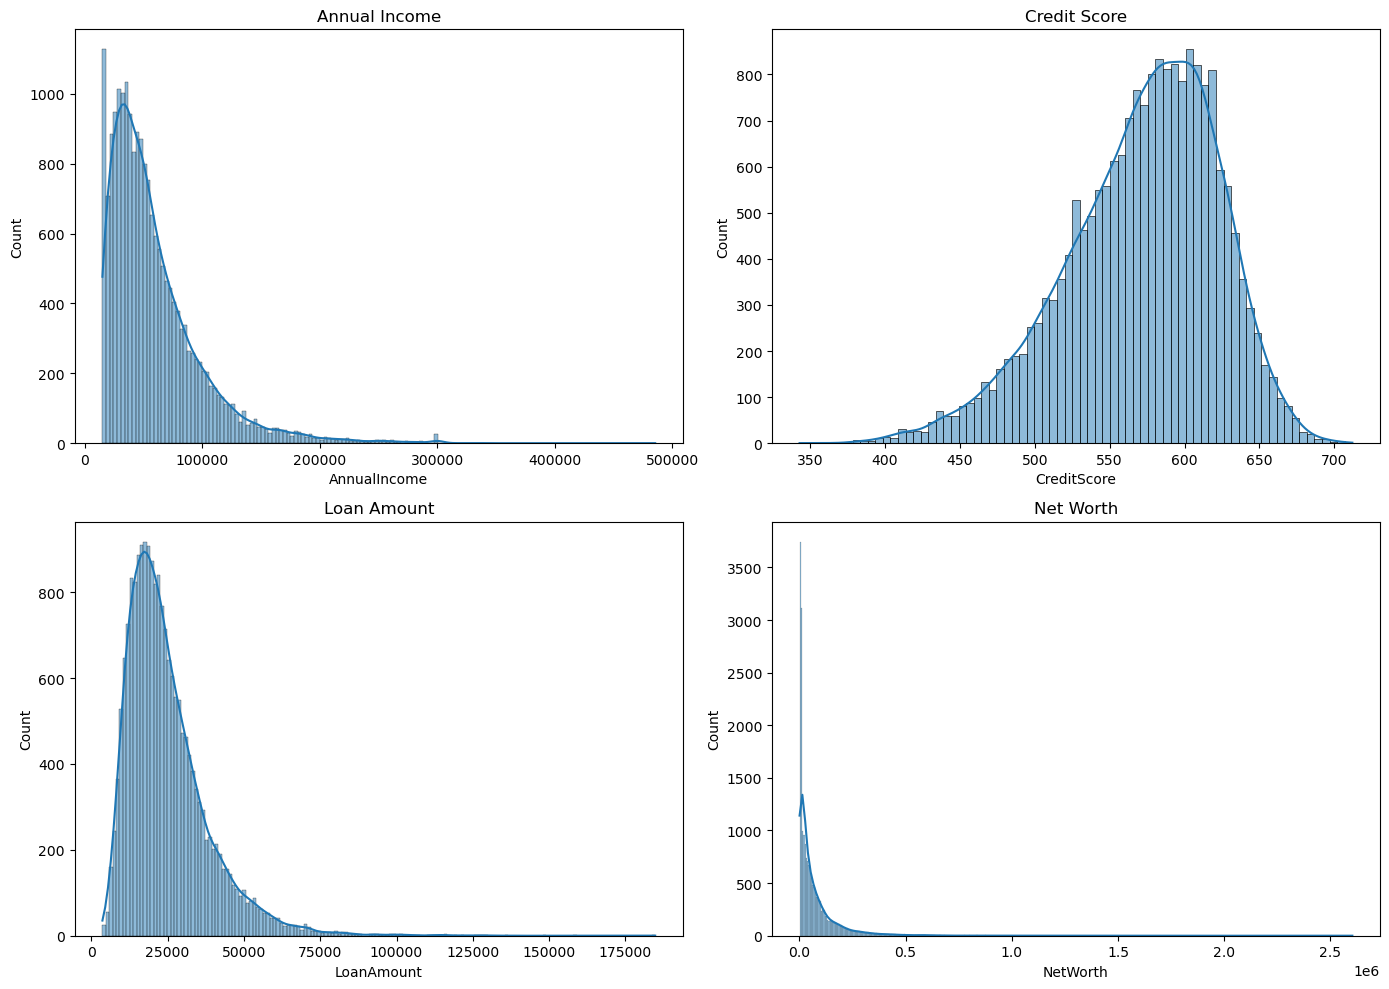

In [12]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14,10)
)

sns.histplot(
    df["AnnualIncome"],
    kde=True,
    ax=axes[0,0]
)

axes[0,0].set_title(
    "Annual Income"
)

sns.histplot(
    df["CreditScore"],
    kde=True,
    ax=axes[0,1]
)

axes[0,1].set_title(
    "Credit Score"
)

sns.histplot(
    df["LoanAmount"],
    kde=True,
    ax=axes[1,0]
)

axes[1,0].set_title(
    "Loan Amount"
)

sns.histplot(
    df["NetWorth"],
    kde=True,
    ax=axes[1,1]
)

axes[1,1].set_title(
    "Net Worth"
)

plt.tight_layout()

plt.show()

### Interpretation
Income, credit score, net worth, and loan amount exhibit substantial variation across applicants and are expected to influence approval decisions.

## Approval Comparison Analysis
Comparing important financial variables between approved and rejected applications.

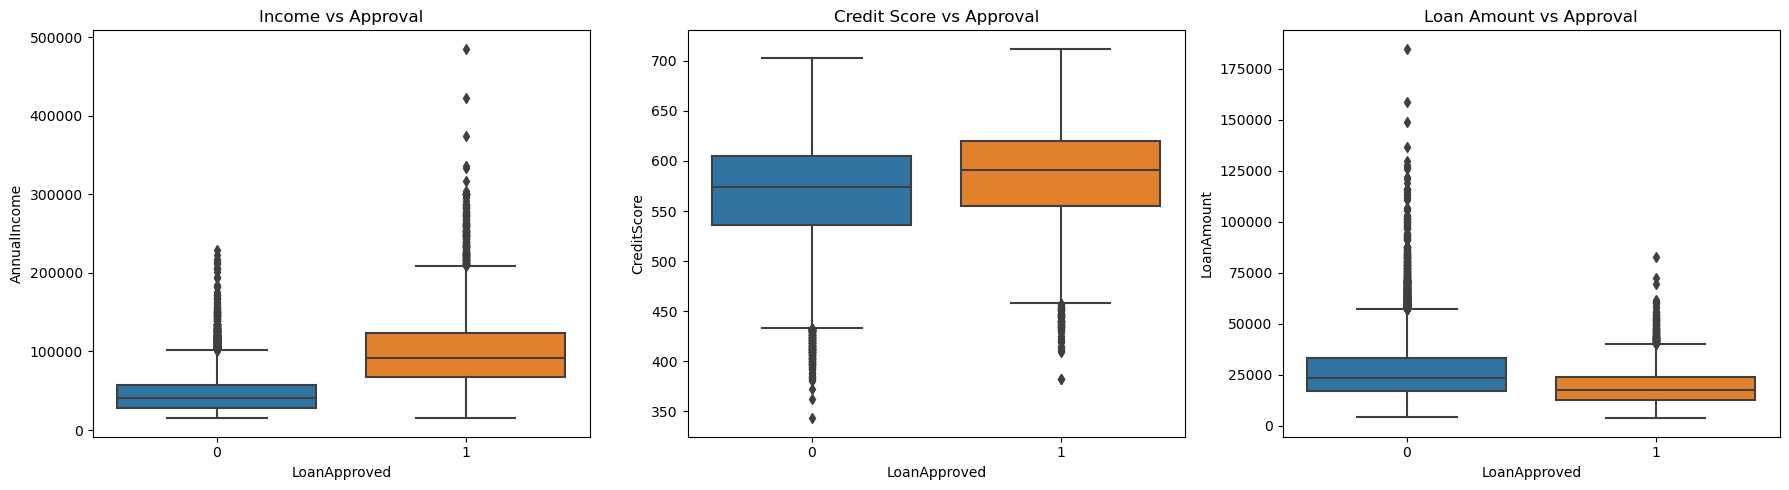

In [13]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18,5)
)

sns.boxplot(
    data=df,
    x="LoanApproved",
    y="AnnualIncome",
    ax=axes[0]
)

axes[0].set_title(
    "Income vs Approval"
)

sns.boxplot(
    data=df,
    x="LoanApproved",
    y="CreditScore",
    ax=axes[1]
)

axes[1].set_title(
    "Credit Score vs Approval"
)

sns.boxplot(
    data=df,
    x="LoanApproved",
    y="LoanAmount",
    ax=axes[2]
)

axes[2].set_title(
    "Loan Amount vs Approval"
)

plt.tight_layout()
plt.show()

### Interpretation
Approved applicants generally demonstrate stronger financial characteristics than rejected applicants, suggesting these variables are important predictors.

## Relationship Analysis
Exploring the relationship between credit score, income, and approval outcomes.

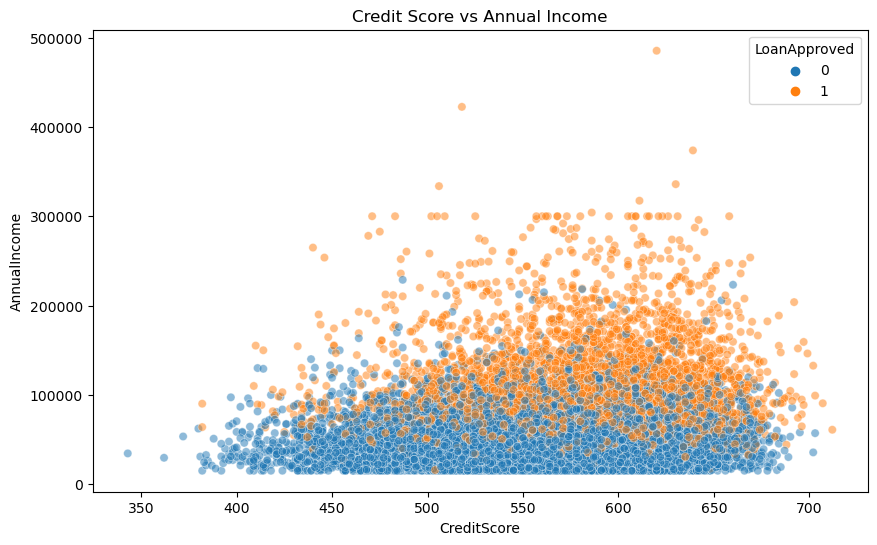

In [14]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="CreditScore",
    y="AnnualIncome",
    hue="LoanApproved",
    alpha=0.5
)

plt.title(
    "Credit Score vs Annual Income"
)

plt.show()

### Interpretation
Applicants with higher income and stronger credit scores appear more likely to receive loan approval.

## Correlation Analysis
Examining relationships among key numerical variables.

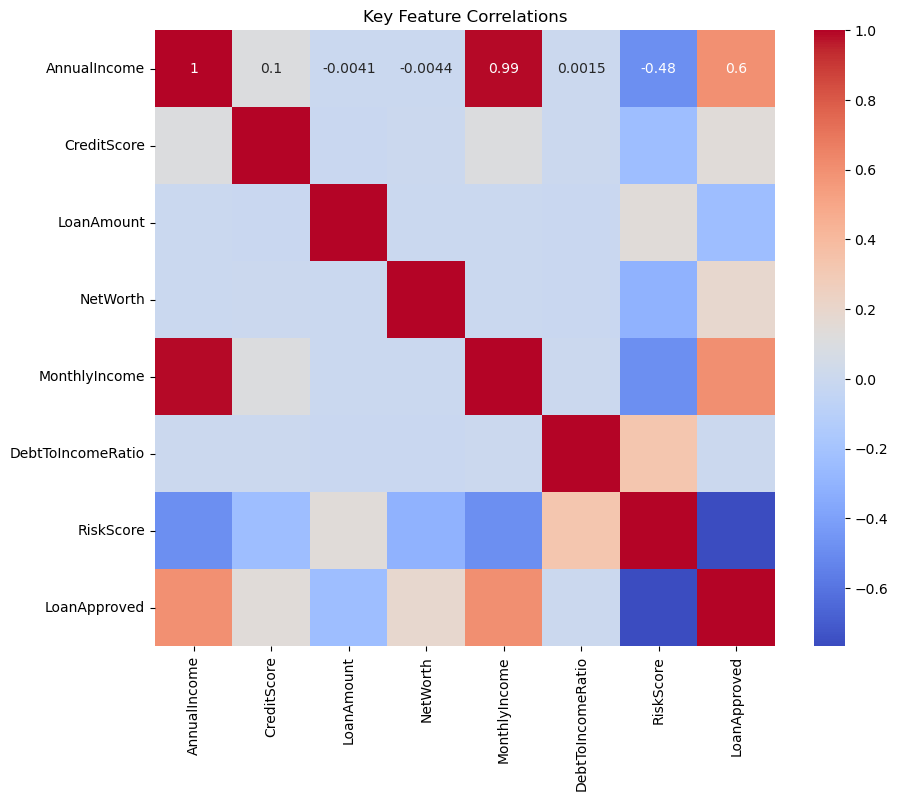

In [15]:
corr_features = [
    "AnnualIncome",
    "CreditScore",
    "LoanAmount",
    "NetWorth",
    "MonthlyIncome",
    "DebtToIncomeRatio",
    "RiskScore",
    "LoanApproved"
]

plt.figure(figsize=(10,8))

sns.heatmap(
    df[corr_features].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title(
    "Key Feature Correlations"
)

plt.show()

### Interpretation
Variables exhibiting stronger relationships with loan approval may contribute more significantly to model predictions.

## EDA Summary
**Key findings**

Approved applicants generally have higher credit scores.
Income appears positively associated with approval.
Debt-related variables influence lending decisions.
Loan approvals are moderately imbalanced.

# Modeling

## Feature and Target Definition
Preparing the predictor variables and target variable for model development.

In [16]:
# Target & Features

X = df.drop(
    columns=[
        "LoanApproved",
        "RiskScore"
    ]
)

y = df["LoanApproved"]

print(X.shape)
print(y.shape)

(20000, 33)
(20000,)


### Interpretation
RiskScore is removed to prevent target leakage and ensure a realistic model evaluation.

## Train-Test Split
Separating the dataset into training and testing subsets.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

## Data Preprocessing (Preprocessing Pipeline)
Applying imputation, scaling, and encoding using a reproducible machine learning pipeline.

In [18]:
numeric_features = X.select_dtypes(
    include=["int64","float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

In [19]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

## Model Development

The following three classification algorithms are developed and compared, in order to identify the best approach that predicts loan approvals.

Logistic Regression
Random Forest
Gradient Boosting


In [20]:
# Logistic Regression

log_model = Pipeline([
    ("preprocessor", preprocessor),

    ("model",
     LogisticRegression(
         max_iter=3000,
         class_weight="balanced",
         random_state= 42
     ))
])

log_model.fit(
    X_train,
    y_train
)

print("Logistic Regression Trained")

Logistic Regression Trained


In [21]:
# Random Forest

rf_model = Pipeline([
    ("preprocessor", preprocessor),

    ("model",
     RandomForestClassifier(
         random_state= 42,
         class_weight="balanced"
     ))
])

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest Trained")

Random Forest Trained


In [22]:
# Gradient Boosting

gb_model = Pipeline([
    ("preprocessor", preprocessor),

    ("model",
     GradientBoostingClassifier(
         random_state= 42
     ))
])

gb_model.fit(
    X_train,
    y_train
)

print("Gradient Boosting Trained")

Gradient Boosting Trained


## Cross Validation

###  Model Comparison
Models are evaluated using 5-fold cross-validation.

ROC-AUC is used because it measures the model's ability to distinguish loan approvals from rejections across multiple classification thresholds.

In [23]:
models = {
    "Logistic Regression": log_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

results = []

for name, model in models.items():

    score = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="roc_auc"
    ).mean()

    results.append(
        [name, score]
    )

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "ROC_AUC"
    ]
)

results_df = results_df.sort_values(
    by="ROC_AUC",
    ascending=False
)

results_df

,Model,ROC_AUC
0,Logistic Regression,0.994569
2,Gradient Boosting,0.985058
1,Random Forest,0.976638


### Interpretation
The model with the highest ROC-AUC demonstrates the strongest ability to separate approved and rejected loan applications.

Logistic Regression achieved the highest cross-validated ROC-AUC score (0.9946) among the three baseline models during 5-fold cross-validation, indicating the strongest ability to distinguish approved and rejected loan applications.

Despite being the simplest model, Logistic Regression provided the strongest predictive performance on this dataset while maintaining high interpretability. Therefore, it was selected as the final model for evaluation and business analysis.

## Hyperparameter Tuning

### Hyperparameter Optimization

GridSearchCV is used to identify the best Random Forest configuration.


In [24]:
param_grid = {

    "model__n_estimators": [
        100,
        200,
        300
    ],

    "model__max_depth": [
        5,
        10,
        None
    ],

    "model__min_samples_split": [
        2,
        5
    ]
}

In [25]:
grid_search = GridSearchCV(
    rf_model,
    param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(
    X_train,
    y_train
)


print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest ROC-AUC:")
print(grid_search.best_score_)



Best Parameters:
{'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 300}

Best ROC-AUC:
0.9777047233660557


## Best Model

In [26]:
best_model = grid_search.best_estimator_

best_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'AnnualIncome',
                                                   'CreditScore', 'Experience',
                                                   'LoanAmount', 'LoanDuration',
                                                   'NumberOfDependents',
                                                   'MonthlyDebtPayments',
                                                   'CreditCardUtilizationRate',
                                                   'NumberOfOpenCreditLines',
                                                   'NumberOfCredi...
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['EmploymentStatus',
                                                   'EducationLevel',
                                                   'MaritalStatus',
                                                   'HomeOwnershipStatus',
                                                   'BankruptcyHistory',
                                                   'LoanPurpose'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        min_samples_split=5, n_estimators=300,
                                        random_state=42))])

### Final Model Selection

Although Random Forest underwent hyperparameter tuning, Logistic Regression maintained superior predictive performance with the highest ROC-AUC score (0.9946), outperforming Gradient Boosting and Random Forest.

Therefore, Logistic Regression was selected as the final model because it provided the strongest predictive performance while maintaining high interpretability.

In [27]:
best_model = log_model

best_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'AnnualIncome',
                                                   'CreditScore', 'Experience',
                                                   'LoanAmount', 'LoanDuration',
                                                   'NumberOfDependents',
                                                   'MonthlyDebtPayments',
                                                   'CreditCardUtilizationRate',
                                                   'NumberOfOpenCreditLines',
                                                   'NumberOfCredi...
                                                   'TotalDebtToIncomeRatio']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['EmploymentStatus',
                                                   'EducationLevel',
                                                   'MaritalStatus',
                                                   'HomeOwnershipStatus',
                                                   'BankruptcyHistory',
                                                   'LoanPurpose'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=3000,
                                    random_state=42))])

In [28]:
# Predictions

y_pred = best_model.predict(X_test)

y_pred_proba = (
    best_model
    .predict_proba(X_test)[:, 1]
)

# Evaluation

## Model Evaluation

Model performance is assessed using Accuracy, Precision, Recall, F1 Score, and ROC-AUC.

In [29]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

roc_auc = roc_auc_score(
    y_test,
    y_pred_proba
)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

Accuracy  : 0.9600
Precision : 0.8748
Recall    : 0.9718
F1 Score  : 0.9207
ROC-AUC   : 0.9946


In [30]:
# OR 
# Putting them in Summary Table
metrics_df = pd.DataFrame({
    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

metrics_df

,Metric,Value
0,Accuracy,0.960000
1,Precision,0.874765
2,Recall,0.971757
3,F1,0.920714
4,ROC-AUC,0.994561


### Classification Report

In [31]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.99      0.96      0.97      3044
           1       0.87      0.97      0.92       956

    accuracy                           0.96      4000
   macro avg       0.93      0.96      0.95      4000
weighted avg       0.96      0.96      0.96      4000



### Interpretation
High recall helps identify applicants who should be approved, while precision helps reduce unnecessary approvals that may increase risk.

### Confusion Matrix
Since the final selected model is Logistic Regression, let's include the confusion matrix figure and a short interpretation in the final report. The confusion matrix provides a detailed breakdown of the model's predictions by comparing actual loan outcomes with predicted outcomes.

It helps identify:

Correct approvals and rejections
False approvals (higher financial risk)
False rejections (lost business opportunities)

This provides a practical assessment of model performance beyond overall accuracy.


<Figure size 600x500 with 0 Axes>

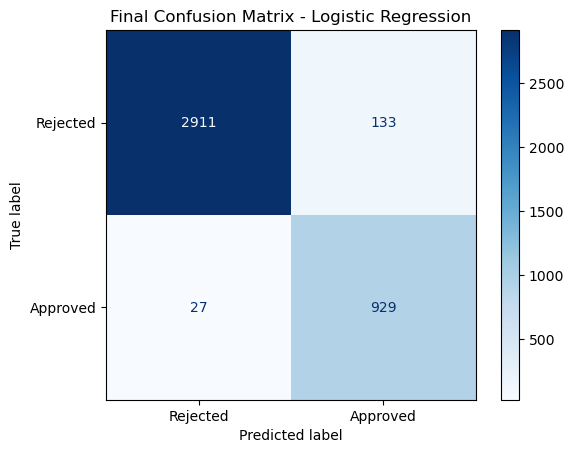

Confusion Matrix:
[[2911  133]
 [  27  929]]


In [32]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"]
).plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Final Confusion Matrix - Logistic Regression"
)

plt.grid(False)

plt.show()

print("Confusion Matrix:")
print(cm)

In [33]:
cm = confusion_matrix(
    y_test,
    y_pred
)

tn, fp, fn, tp = cm.ravel()

false_approval_cost = fp * 50000

lost_revenue_cost = fn * 8000

total_cost = (
    false_approval_cost +
    lost_revenue_cost
)

print(f"True Negatives : {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives : {tp}")

print("\nBusiness Costs")

print(
    f"False Approval Cost: ${false_approval_cost:,.2f}"
)

print(
    f"Lost Revenue Cost: ${lost_revenue_cost:,.2f}"
)

print(
    f"Total Business Cost: ${total_cost:,.2f}"
)

True Negatives : 2911
False Positives: 133
False Negatives: 27
True Positives : 929

Business Costs
False Approval Cost: $6,650,000.00
Lost Revenue Cost: $216,000.00
Total Business Cost: $6,866,000.00


### Interpretation
The confusion matrix shows the number of correctly and incorrectly classified loan applications.

True Positives (TP): Correctly approved applications.
True Negatives (TN): Correctly rejected applications.
False Positives (FP): Applications incorrectly approved, representing potential financial risk.
False Negatives (FN): Applications incorrectly rejected, representing missed lending opportunities.

The relatively low number of misclassifications indicates that the Logistic Regression model is highly effective at distinguishing between approved and rejected loan applications.

### ROC Curve

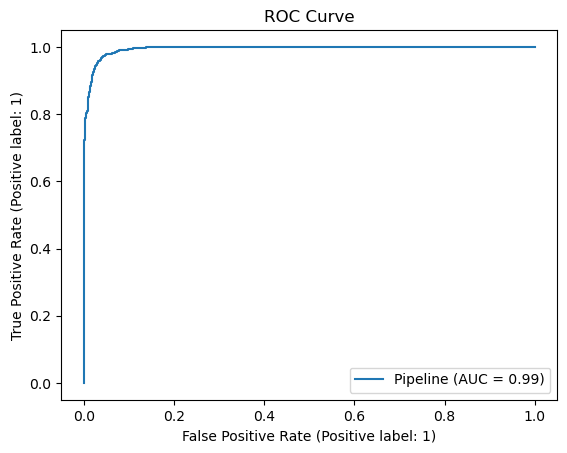

In [34]:
RocCurveDisplay.from_estimator(
    best_model,
    X_test,
    y_test
)

plt.title("ROC Curve")

plt.show()

### Interpretation
A larger area under the ROC curve indicates stronger model discrimination between approved and rejected applications.

## Feature Importance Analysis

For Logistic Regression, feature importance is determined using the magnitude of model coefficients.

Features with larger absolute coefficient values have a stronger influence on loan approval predictions.

In [35]:
feature_names = (
    best_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    best_model
    .named_steps["model"]
    .coef_[0]
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": np.abs(coefficients)
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

In [36]:
# feature_importances_ only exists for tree-based models such as Random Forest.

#feature_names = (
#    best_model
#    .named_steps["preprocessor"]
#    .get_feature_names_out()
#)

#importance = (
#    best_model
#    .named_steps["model"]
#    .feature_importances_
#)

#importance_df = pd.DataFrame({
#    "Feature": feature_names,
#    "Importance": importance
#})

#importance_df = (
#    importance_df
#    .sort_values(
#        by="Importance",
#        ascending=False
#    )
#)

#importance_df.head(15)

In [37]:
# Feature Importance (Logistic Regression)
feature_names = (
    best_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    best_model
    .named_steps["model"]
    .coef_[0]
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Coefficient,Importance
26,num__TotalDebtToIncomeRatio,-8.548901,8.548901
24,num__InterestRate,-5.296842,5.296842
19,num__MonthlyIncome,4.586080,4.586080
44,cat__BankruptcyHistory_Yes,-3.279891,3.279891
43,cat__BankruptcyHistory_No,3.278965,3.278965
22,num__NetWorth,2.754936,2.754936
32,cat__EducationLevel_Doctorate,2.660400,2.660400
33,cat__EducationLevel_High School,-2.534490,2.534490
4,num__LoanAmount,-2.220877,2.220877
29,cat__EmploymentStatus_Unemployed,-2.122845,2.122845


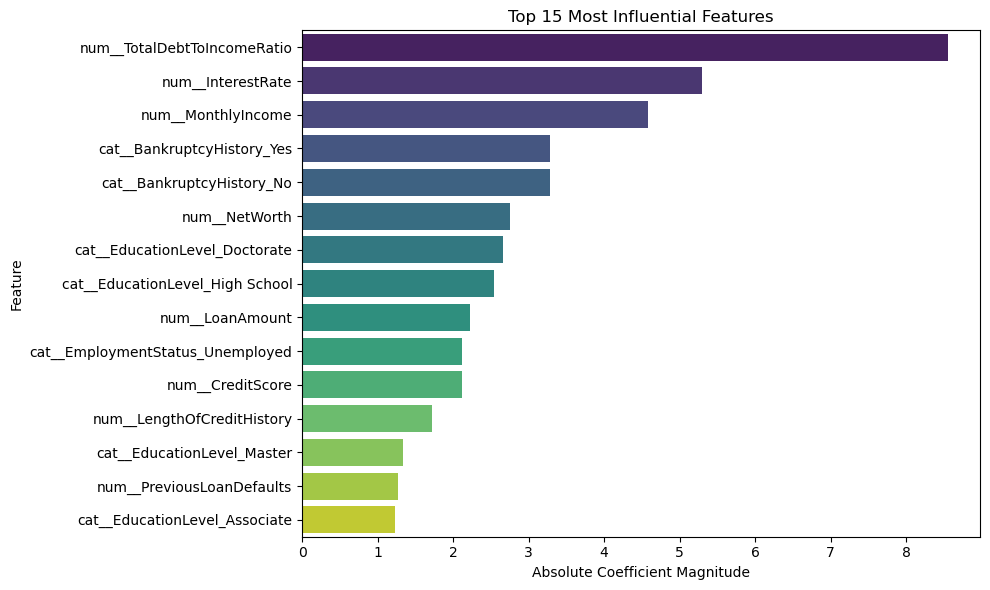

In [38]:
# Plot Top 15 Features

top15 = importance_df.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top15,
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title(
    "Top 15 Most Influential Features"
)

plt.xlabel("Absolute Coefficient Magnitude")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Interpretation
The most influential variables represent the strongest drivers of loan approval decisions and provide insight into applicant risk profiles.

## Business Cost Analysis
Model performance is translated into financial impact to evaluate practical business value.

Business Interpretation
The most influential features represent the primary drivers of loan approval decisions.

Features with higher importance contribute more strongly to the model's prediction and provide insight into the financial characteristics associated with lower or higher lending risk.

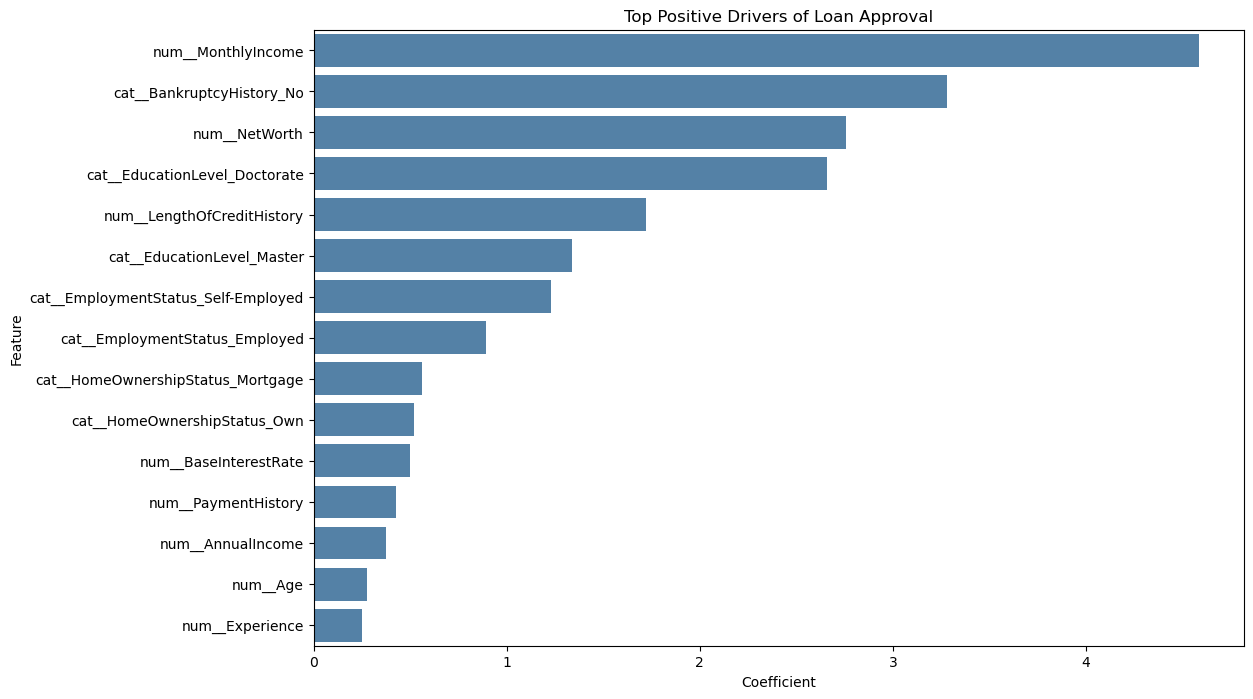

In [39]:
top15_signed = importance_df.sort_values(
    by="Coefficient",
    ascending=False
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top15_signed.head(15),
    x="Coefficient",
    y="Feature",
    color="steelblue"
)

plt.title(
    "Top Positive Drivers of Loan Approval"
)

plt.show()

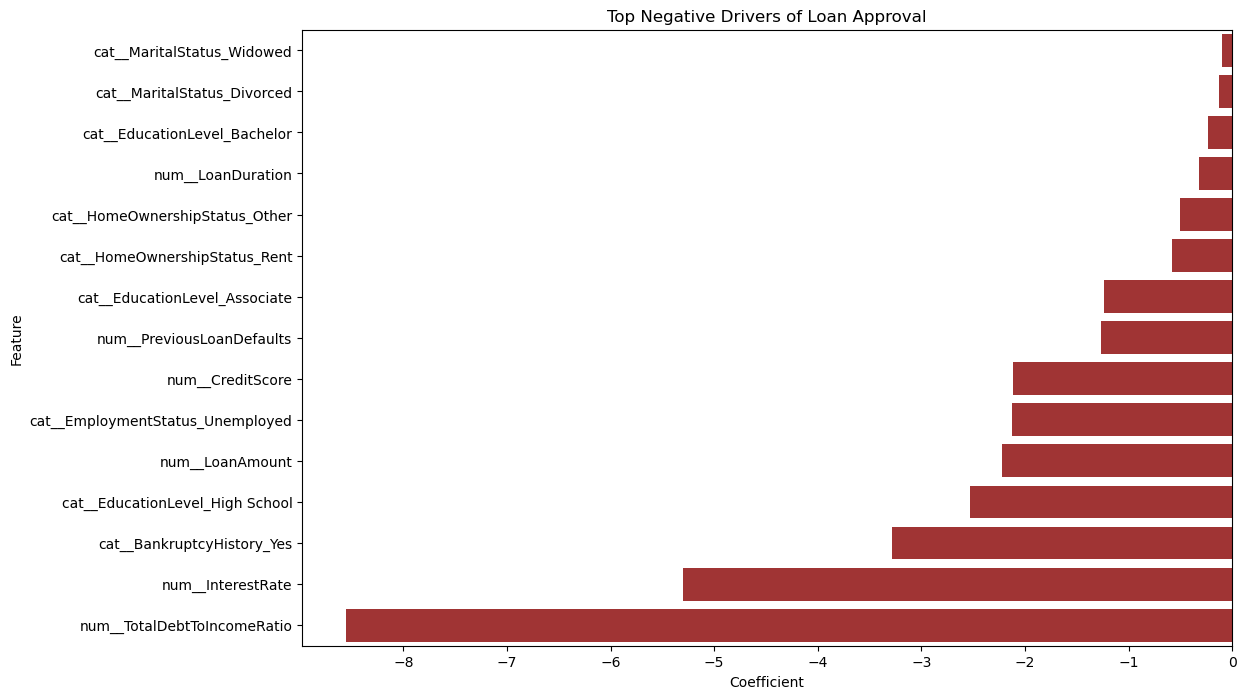

In [40]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=top15_signed.tail(15),
    x="Coefficient",
    y="Feature",
    color="firebrick"
)

plt.title(
    "Top Negative Drivers of Loan Approval"
)

plt.show()

## Conclusion


This project developed and evaluated machine learning models to predict loan approval outcomes using applicant financial, credit, and demographic information.

**Key Findings**
Logistic Regression achieved the highest cross-validated ROC-AUC score (0.9946), outperforming Random Forest and Gradient Boosting.
Financial and credit-related variables were the strongest predictors of loan approval.
The preprocessing pipeline effectively handled missing values and categorical features.
Business cost analysis demonstrated the value of reducing both false approvals and false rejections.

**Recommendation**
Logistic Regression is recommended as the final model due to its superior predictive performance and high interpretability. The model can support data-driven loan approval decisions, improve consistency, and help manage lending risk more effectively.